# Assigment 5: Unsupervised Learning and Resampling
## Imports

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

## Question 1. Customer Segmentation with K-Means

### a) Load Data
- Source: ([https://archive.ics.uci.edu/dataset/292/wholesale+customers])
- Source: [(https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.agg.html)]

First, we load the data, and inspect the shape, data types, and missing values. We also find the minimum value, maximum value, mean, and median for each variable.

In [9]:
# fetch dataset 
wholesale_customers = fetch_ucirepo(id=292) 
  
# data (as pandas dataframes) 
X = wholesale_customers.data.features 
X = X.drop(columns=['Channel'])
  
# Show first five rows.
display(X.head(5))

# Check shape, data types, and missing values
print("Shape:", X.shape)
display(X.dtypes.to_frame(name="Data type"))
display(X.isna().sum().to_frame(name="Missing values"))

# Report summary statistics for each spending variable
summary = X.agg(["min", "max", "mean", "median"]).T
display(summary)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


Shape: (440, 6)
Data types:


,Data type
Fresh,int64
Milk,int64
Grocery,int64
Frozen,int64
Detergents_Paper,int64
Delicassen,int64


Missing values:


,Missing values
Fresh,0
Milk,0
Grocery,0
Frozen,0
Detergents_Paper,0
Delicassen,0


,min,max,mean,median
Fresh,3.0,112151.0,12000.297727,8504.0
Milk,55.0,73498.0,5796.265909,3627.0
Grocery,3.0,92780.0,7951.277273,4755.5
Frozen,25.0,60869.0,3071.931818,1526.0
Detergents_Paper,3.0,40827.0,2881.493182,816.5
Delicassen,3.0,47943.0,1524.870455,965.5


Each variable has an `integer` data type. Spending is continuous, but appears ti be rounded to the nearest dollar. In every category, the mean exceeds the median, indicating right-skewed spending, with a few high-spending customers raising the average. The very high maxima suggest high variation and possible outliers.

#### Plot histogram
- Source: ([https://www.geeksforgeeks.org/python/how-to-create-a-histogram-from-pandas-dataframe/])

A histogram shows how often values fall within intervals. Pandas DataFrames provide `.hist()` to create Matplotlib plots. The x-axis corresponds to the annual spending, while the y-axis corresponds to the number of customers.

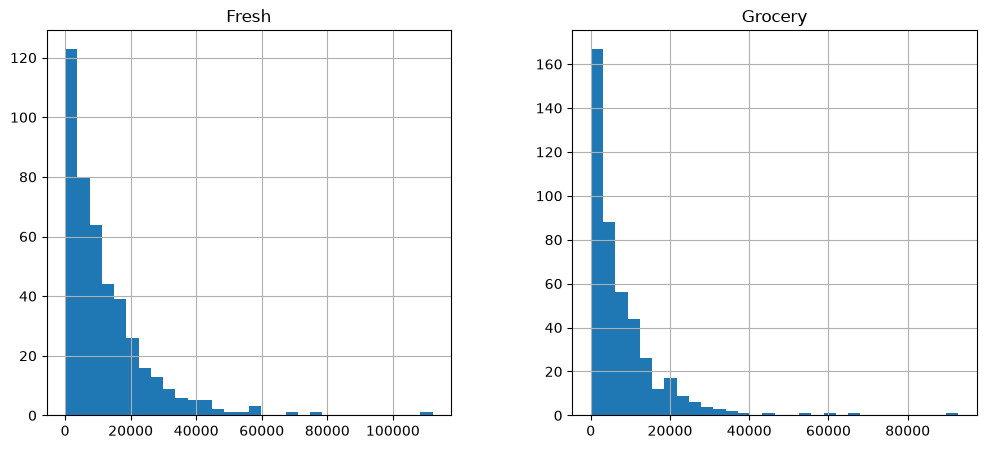

In [20]:
# Plot histograms
X[["Fresh", "Grocery"]].hist(bins=30, figsize=(12, 5))
plt.show()

Both distributions are strongly **right-skewed**. Most customers spend relatively little, while a small number of high-spening outliers spend much more. This creates a long right-tail in both plots.

### b) Data Normalization
- Source: [(https://medium.com/@noorfatimaafzalbutt/understanding-np-log-and-np-log1p-in-numpy-99cefa89cd30)]

The `log` function is often used to transform data to acheive normality is statistical models. `log1p()` calculates $\log(1 + x)$ for each element `x` in the array. This function is useful when $x$ is close to zero. It is often used in preprocessing of highly skewed data. The log transformation reduces the strong right skew and compresses extreme values, making the distributions easier to compare.

In [22]:
X_log = np.log1p(X)

#### Zero Mean and Unit Variance Normalization
- Source: ([https://www.geeksforgeeks.org/data-science/what-is-zero-mean-and-unit-variance-normalization/])

First, mean-centering subtracts each feature’s mean $\mu$, giving it a mean of zero. Then, dividing by its standard deviation $\sigma$ gives it a variance of one: $ \bar{x} = \frac{x - \mu}{\sigma}$. This can help algorithms converge faster, prevent features from dominating, and make features easier to compare. It also reduces the impact of outliers. 

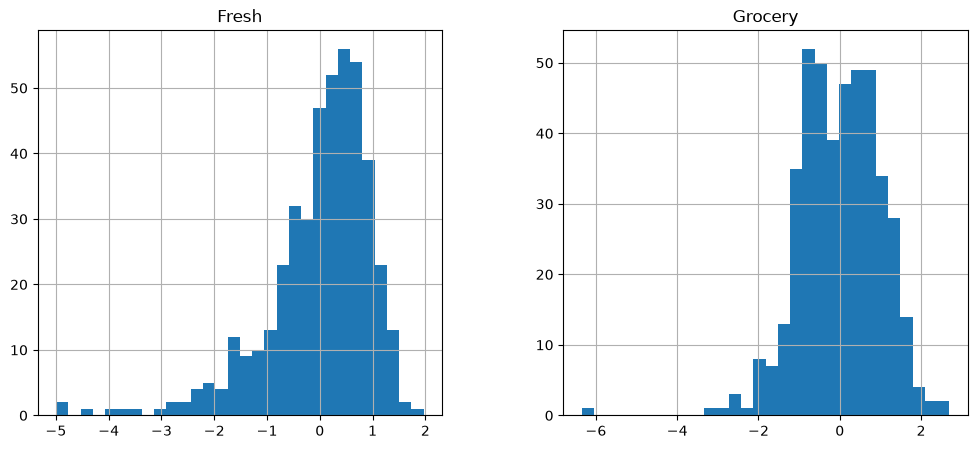

In [23]:
X_scaled = (X_log - X_log.mean()) / X_log.std()
X_scaled[["Fresh", "Grocery"]].hist(bins=30, figsize=(12, 5))
plt.show()

The original data is strongly right-skewed. The transformed and normalized data has a much more balanced distribution, though some outliers remain. The x-axis shows the normalized log-spending values. The y-axis shows the number of customers in each new bin. The total number of customers remains the same.

### c) K-Means Clustering
- Source: ([https://realpython.com/k-means-clustering-python/])

Clustering helps reveal meaningful and useful patterns in data. Three common types are partitioning, hierarchical, and density-based clustering. Partitioning divides data into non-overlapping groups. Hierarchical clustering builds a hierarchy using a bottom-up (agglomerative) or top-down (divisive) approach. Density-based clustering groups points based on their density in a region.

K-means begins by choosing $k$ centroids, where $k$ is the desired number of clusters. A centroid represents a cluster’s center. The algorithm iterates through two steps. The expectation step assigns each point to its nearest centroid. The maximization step calculates each cluster’s mean and updates its centroid. After the centroids converge, cluster quality can be assessed using the sum of squared errors (SSE), which the algorithm aims to minimize. Because initialization is random, repeated runs on the same data may produce different assignments. K-means can be implemented in Python using `scikit-learn`.

This code evaluates K-means clustering for 2 to 6 clusters. For each number of clusters $k$, we ue `fit_predict(X_scaled)` to train the model on the log-normalized data and return each point's cluster label. The model's inertia is the within-cluster squared distances, and the silhoutte score defines how well-separated the clusters are.

In [27]:
results = []

for k in range(2, 7):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = kmeans.fit_predict(X_scaled)

    results.append({
        "k": k,
        "Inertia": kmeans.inertia_,
        "Silhouette score": silhouette_score(X_scaled, labels)
    })

results_table = pd.DataFrame(results)
display(results_table)

,k,Inertia,Silhouette score
0,2,1839.873014,0.290328
1,3,1549.890824,0.259416
2,4,1383.710781,0.188495
3,5,1263.271749,0.191585
4,6,1172.088727,0.200887


The results show that inertia decreases as $k$ increases, since more clusters allow the model to fit the data more closely. The silhouette score is highest at $k=2$, indicating the clearest cluster separation among the tested values, although the separation remains modest.

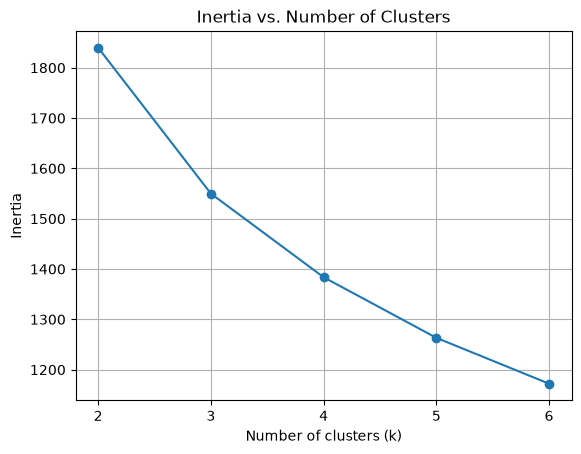

In [28]:
plt.plot(results_table["k"], results_table["Inertia"], marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Inertia vs. Number of Clusters")
plt.xticks(results_table["k"])
plt.grid(True)
plt.show()

The plot shows that inertia decreases as $k$ increases. Inertia alone cannot identify the best $k$ because it always decreases as clusters are added, even if the extra clusters don't reveal any meaningful information. For example, if $k$ equals the number of data points, the model will fit the data perfectly, but will be useless.

### d) Analyze Clusters

This code fits a K-means model with $k=2$ clusters, corresponding to the model with the best silhoette score. Next, we turn the cluster labels into a labeled one-dimensional Pandas `Series`. `.value_counts()` counts how many customers have each label. `.sort_index()` orders the counts by cluster label. `.to_frame()` converts the `Series` into a one-column DataFrame for display. `.rename()` renames the `Series` to make the table clearer.


In [30]:
# Fit a separate k=2 model
kmeans_2 = KMeans(n_clusters=2, n_init=10, random_state=42)
labels_2 = kmeans_2.fit_predict(X_scaled)

# Cluster sizes
cluster_sizes = (
    pd.Series(labels_2, name="Cluster")
    .value_counts()
    .sort_index()
    .rename("Customer count")
    .to_frame())
display(cluster_sizes)

,Customer count
Cluster,
0,252
1,188


`X.assign` adds each customer's cluster label to the original untransformed data. We then use `groupby(...).median()` to calculate the median spending in each original feature for each customer.

In [31]:
# Median spending in the original, untransformed variables
X_clustered = X.assign(Cluster=labels_2)
median_spending = X_clustered.groupby("Cluster")[X.columns].median()
display(median_spending)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
0,10347.5,1871.0,2406.0,2225.0,327.5,749.5
1,5406.5,7690.5,11527.0,1061.5,4495.0,1388.5


To make the results easier to see, we also generate a bar graph.

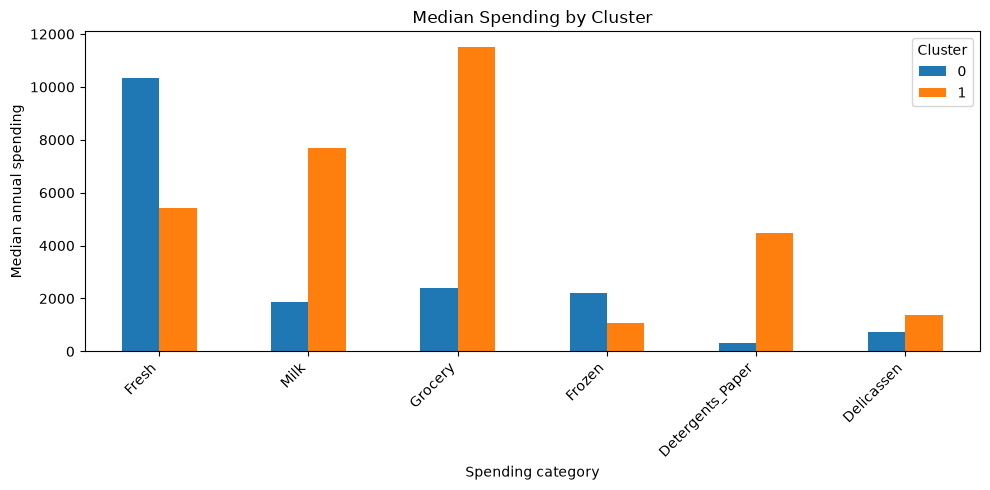

In [32]:
ax = median_spending.T.plot(kind="bar", figsize=(10, 5))
ax.set_xlabel("Spending category")
ax.set_ylabel("Median annual spending")
ax.set_title("Median Spending by Cluster")
ax.legend(title="Cluster")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Cluster 0 (252 customers) has a higher median spend on `Fresh` and lower median spending in most other categories. Cluster 1 (188 customers) spends more on `Milk`, `Grocery`, and `Detergents_Paper`. One possible explanation is that Cluster 0 includes businesses such as restaurants that need more fresh products, while Cluster 1 includes customers who buy more packaged groceries and household supplies. We name Cluster 0 `Business` and Cluster 1 `Household`. 

### e) K-Means Limitations

The clusters only show patterns in the data, they do not show what caused those patterns. The identities and characteristics of the customers are still unknown. Additionally, the silhouette score of 0.29 suggests substantial overlap between customers. Overall, the clustering revealed little meaningful structure in the data. K-means clustering assigns each customer to exactly one cluster. However, similar customers can still end up in different clusters, causing overlap between the groups. This was seen by the low silhouette score shown by this model. 

Even though the K-means results are limited, the profiles could still help a retailer target advertisements of product recommendations to certain customer types.

## Question 2. PCA and Gaussian Mixture Models
- Source: [(https://www.datacamp.com/tutorial/principal-component-analysis-in-python)]

Principal Component Analysis (PCA) reduces dataset dimensionality by transforming potentially correlated variables into a smaller set of variables called principal components that capture most of the original information. PCA helps visualize datasets with many features and is often used to preprocess data for machine-learning algorithms. Reducing dimensions can lessen the curse of dimensionality, where added features impair model performance. PCA may also reduce overfitting and multicollinearity. PCA can be describes as finding the eigenvectors of the covariance matrix to identify the directions of maximum variance in the data.

Principal components have both magnitude and direction. The direction represents across which principal axes the data has the most variance. The magnitude signifies the amount of variance that principal component captures when the data is projected onto that axis. The principal components form a straight line. The first principal component captures the most variance in the data. Each subsequent principal compoenent is orthogonal to the last and has less variance. Given a set of $x$ correlated variables over $y$ samples, we obstain a set of $u$ uncorrelated principal compoenents.

### a) Cumulative Explained Variance

We import the `PCA` module from the `sklearn` library. We choose the number of components and pass the log-normalized data. 

In [36]:
# Fit PCA using all six principal components.
pca = PCA(n_components=6)
X_pca = pca.fit_transform(X_scaled)

This code creates a table summarizing how much variance each principal component explains. The `Component` column generates the labels `PC1`, `PC2`, ect.. The `Explained variance ratio` column shows the proportional of total variance explained by each component. Numpy's `cumsum` cumultively adds those proportions, so the column `Cumulatively explained variance` shows the total variance captured by the first $n$ components.

In [37]:
variance_table = pd.DataFrame({
    "Component": [f"PC{i}" for i in range(1, len(pca.explained_variance_ratio_) + 1)],
    "Explained variance ratio": pca.explained_variance_ratio_,
    "Cumulative explained variance": np.cumsum(pca.explained_variance_ratio_)})

display(variance_table)

,Component,Explained variance ratio,Cumulative explained variance
0,PC1,0.440778,0.440778
1,PC2,0.271949,0.712727
2,PC3,0.106984,0.819711
3,PC4,0.101033,0.920744
4,PC5,0.048763,0.969507
5,PC6,0.030493,1.000000


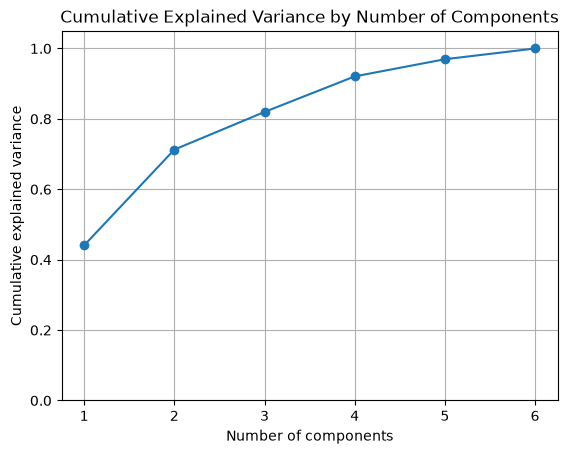

In [38]:
# Plot cumulative explained variance against the number of components
components = range(1, len(variance_table) + 1)

plt.plot(
    components,
    variance_table["Cumulative explained variance"],
    marker="o")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("Cumulative Explained Variance by Number of Components")
plt.xticks(components)
plt.ylim(0, 1.05)
plt.grid(True)
plt.show()

PC1 explains about 44% of the variance, and PC2 adds about 27%. Together, they capture roughly 71% of the total variation. At six principal components, all of the variantion of the original dataset is captured. To retain over 90% of the original information, at least three components must be used. These results show how much we can reduce the dimensionality without losing information.

### b) 2D-Projection

This code plots `PC1` versus `PC2`, using a different color for each K-means cluster. `np.unique(labels_2)` gets the cluster labels. The mast selects the rows belonging to the current cluster. `x_pca[mask, 0]` and `x_pca[mask, 1]` get `PC1` and `PC2` data points. The x-axis shows each customer's `PC1` score, while the y-axis shows each customer's `PC2` score. The axes are labeled with their explained variance percentages.

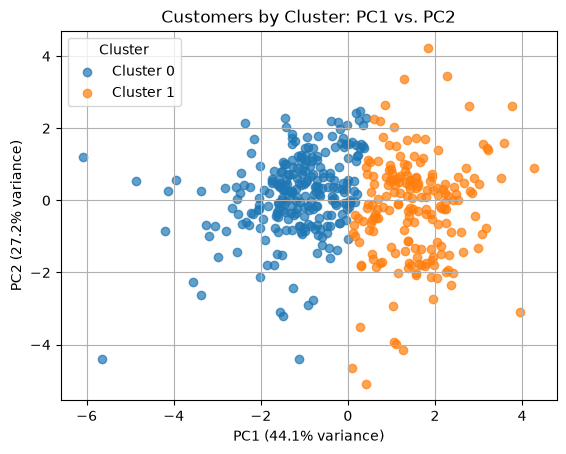

In [39]:
for cluster in np.unique(labels_2):
    mask = labels_2 == cluster
    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=f"Cluster {cluster}",
        alpha=0.7)

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
plt.title("Customers by Cluster: PC1 vs. PC2")
plt.legend(title="Cluster")
plt.grid(True)
plt.show()

The clusters are partly separated along `PC1`. Cluster 0 tends to have lower scores, while Cluster 1 has higher scores. They overlap near the center so the groups are not completely distinct. The plot only shows `PC1` and `PC2` which retain about `71%` of the variation and ommits the other four components. Customer that appear close in the 2D projection may be different in the other four dimensions. This plot alone does not show how much the clusters overlap in all six dimensions. 

### c) Guassian Mixture Model
- Source: [(https://youtu.be/C7jhwN6H9LU)]
- Source: [(https://jakevdp.github.io/PythonDataScienceHandbook/05.12-gaussian-mixtures.html)]

A Gaussian mixture model (GMM) represents data as a weighted combination of Gaussian distributions, each with its own mean and variance. Each distribution is called a component, and its weight represents the probability that a sample came from that component.

GMMs use soft clustering, which is useful when clusters overlap and data cannot be clearly separated. Unlike K-means, which assigns each data point to one cluster, a GMM gives each point a probability of belonging to every cluster. Each cluster is modeled by a Gaussian distribution.

Like K-means, GMMs use an iterative approach called expectation-maximization (EM):

1. Initialize the $k$ Gaussian distributions.
2. Calculate each data point’s responsibility, or probability of belonging to each distribution. These probabilities sum to one for each point.
3. Use the responsibilities to update the Gaussian distributions.
4. Repeat steps 2 and 3 until the model converges, meaning its parameters change very little between iterations.

For multidimensional data, each component has a mean vector and a covariance matrix.